# Amortized methods in geostatistics

**Check list execution**
* file
* path
* batch_size
* n_epoch

In [1]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

import numpy as np

import random
from tqdm import tqdm
import time
import os
import torchmin

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import torch_geometric
from torch_geometric.data import Data
from torch_geometric.nn import global_mean_pool, GCNConv

from torch_geometric.data import Dataset
from torch_geometric.loader import DataLoader
from torch_geometric.data import Batch

from torch_geometric.utils import to_scipy_sparse_matrix
from torch_geometric.nn.conv import MessagePassing
from torch_geometric.utils import scatter
from torch_geometric.nn import aggr

In [3]:
from scipy.sparse.csgraph import connected_components
from scipy.spatial import cKDTree
from scipy.optimize import minimize
import scipy.linalg as linalg

In [4]:
import gstlearn as gl
import gstlearn.plot as gp
import gstlearn.document as gdoc
gdoc.setNoScroll()

<IPython.core.display.Javascript object>

In [5]:
device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")

In [122]:
file = "data/data_spatiotemporal_small"

os.makedirs(file, exist_ok=True)
os.makedirs(file+"/samples", exist_ok=True)
os.makedirs(file+"/grids", exist_ok=True)

## Simulation

### Sampling

In [134]:
def temporal_sample(nb_min=20, nb_max=20, t_min=0, t_max=5.):
    nb = np.random.randint(nb_min, nb_max+1)
    time_steps = np.random.random(nb)
    time_steps = t_min + (t_max - t_min) * time_steps
    time_steps = np.sort(time_steps)
    return time_steps

In [135]:
def sampling_matern(lambdaParent,lambdaDaughter,timeSteps=None, radiusCluster=.05):

    xMin = 0
    xMax = 1
    yMin = 0
    yMax = 1

    rExt = radiusCluster  
    xMinExt = xMin - rExt
    xMaxExt = xMax + rExt
    yMinExt = yMin - rExt
    yMaxExt = yMax + rExt

    xDeltaExt = xMaxExt - xMinExt
    yDeltaExt = yMaxExt - yMinExt
    areaTotalExt = xDeltaExt * yDeltaExt  

    numbPointsParent = np.random.poisson(areaTotalExt * lambdaParent)  
    
    xxParent = xMinExt + xDeltaExt * np.random.uniform(0, 1, numbPointsParent)
    yyParent = yMinExt + yDeltaExt * np.random.uniform(0, 1, numbPointsParent)

    numbPointsDaughter = np.random.poisson(lambdaDaughter, numbPointsParent) 
    numbPoints = sum(numbPointsDaughter)

    theta = 2 * np.pi * np.random.uniform(0, 1, numbPoints) 
    rho = radiusCluster * np.sqrt(np.random.uniform(0, 1, numbPoints)) 
    xx0 = rho * np.cos(theta)
    yy0 = rho * np.sin(theta)

    xx = np.repeat(xxParent, numbPointsDaughter)
    yy = np.repeat(yyParent, numbPointsDaughter)

    xx = xx + xx0
    yy = yy + yy0

    booleInside = ((xx >= xMin) & (xx <= xMax) & (yy >= yMin) & (yy <= yMax))
    xx = xx[booleInside]
    yy = yy[booleInside]

    if timeSteps is None :
        timeSteps = temporal_sample()
    zz = timeSteps.repeat(len(xx))
    
    xx = np.tile(xx,len(timeSteps))
    yy = np.tile(yy,len(timeSteps))

    sample = gl.Db()
    sample.addColumns(xx,"x1")
    sample.addColumns(yy,"x2")
    sample.addColumns(zz,"x3")
    sample.setLocators(["x1","x2","x3"],gl.ELoc.X)

    return sample


def grid(size=50,timeSize=10):

    xx = np.repeat(np.linspace(0,1,size),size)
    yy = np.tile(np.linspace(0,1,size),size)
    
    if timeSteps is None :
        timeSteps = temporal_sample()
    zz = timeSteps.repeat(size*size)
    xx = np.tile(xx,timeSize)
    yy = np.tile(yy,timeSize)

    sample = gl.Db()
    sample.addColumns(xx,"x1")
    sample.addColumns(yy,"x2")
    sample.addColumns(zz,"x3")
    sample.setLocators(["x1","x2","x3"],gl.ELoc.X)

    return sample 

theta_size = 2

In [136]:
def simulation_matern(sample, theta_range, theta_std):

    model = gl.Model.createFromParam(type=gl.ECov.MATERN, range = theta_range, param = 1, sill = theta_std**2, flagRange=False)  
    # model = gl.Model.createFromParam(type=gl.ECov.MATERN, range = theta_range*np.sqrt(8), param = 1, sill = theta_std**2)
    err = gl.simtub(None, sample, model, None, nbsimu=1, seed=0, nbtuba = 5000)  # nbtuba = 1000

    return sample

In [137]:
# sample = grid(timeSize=10) 
sample = sampling_matern(20,20)
theta_range, theta_std = .1, 1.
sample = simulation_matern(sample, theta_range, theta_std)

fig, ax = plt.subplots(figsize=(5,5))

def update(i):
    ax.cla()
    ax.scatter(
        sample['x1'][sample['x3']==np.unique(sample['x3'])[i]],
        sample['x2'][sample['x3']==np.unique(sample['x3'])[i]],
        c=sample['Simu'][sample['x3']==np.unique(sample['x3'])[i]],
        # sample['x1'][sample['x2']==sample['x2'][i]],
        # sample['x3'][sample['x2']==sample['x2'][i]],
        # c=sample['Simu'][sample['x2']==sample['x2'][i]],
        s=10,
        cmap='viridis'
    )
    # ax.set_xlim(0,1)
    # ax.set_ylim(0,1)
    ax.set_title(f"Time {np.unique(sample['x3'])[i]:.4f}s")

ani = FuncAnimation(fig, update, frames=len(np.unique(sample['x3'])), interval=300)

plt.close()

HTML(ani.to_jshtml())

In [139]:
def datamaker(constant_product, n, m, as_grid=False, range_min=.05, range_max=.25,std_min=.1, std_max=1.,lambdaParent_min=10,lambdaParent_max=60, timeSteps=None, radiusCluster = 0.15):

    datalist=[]

    range_list = np.random.uniform(range_min,range_max,m)
    std_list = np.random.uniform(std_min, std_max,m)
    lambdaParent = np.random.uniform(lambdaParent_min, lambdaParent_max,(n,m))
    lambdaDaughter = constant_product / lambdaParent

    print("i : ", end='')

    for i in range(n):

        print(i, end='|')

        # pi = torch.randperm(m)

        # if timeSteps is None :
        #     timeSteps = temporal_sample()

        for j in range(m):

            if as_grid :
                sample = grid() 
            else :
                sample = sampling_matern(lambdaParent[i,j],lambdaDaughter[i,j],timeSteps=timeSteps,radiusCluster=radiusCluster)
            simu = simulation_matern(sample, range_list[j], std_list[j])
    
            theta = (range_list[j], std_list[j])
    
            datalist.append((simu,np.unique(simu['x3']),theta,j))

            print('.', end='')

    return datalist

In [140]:
n_points = 250

n_train = 3
m_train = 20

n_test = 2
m_test = 15

In [141]:
batch_size = 5
n_epochs = 150
n_epochs_test = 10

In [142]:
sampling_train = datamaker(n_points,
                           n_train,
                           m_train,
                           as_grid=False,
                           radiusCluster = 0.05)

i : 0|....................1|....................2|....................

In [143]:
sampling_test = datamaker(n_points, 
                          n_test, 
                          m_test, 
                          as_grid=False,
                          radiusCluster = 0.05)

i : 0|...............1|...............

### Grid

In [144]:
def points_to_grid(sample, nb_bins=100):
    
    bin_size = 1.0 / nb_bins

    x1 = torch.tensor(sample['x1'], dtype=torch.float32)
    x2 = torch.tensor(sample['x2'], dtype=torch.float32)
    x3 = torch.tensor(sample['x3'], dtype=torch.float32)
    values = torch.tensor(sample['Simu'], dtype=torch.float32)

    ix = (x1[x3 == x3[0]] / bin_size).long()
    iy = (x2[x3 == x3[0]] / bin_size).long()

    ix = torch.minimum(ix, torch.ones_like(ix, dtype=int) * (nb_bins - 1))
    iy = torch.minimum(iy, torch.ones_like(iy, dtype=int) * (nb_bins - 1))

    flat_idx = ix * nb_bins + iy

    time_size = len(x3.unique())
    values = values.reshape((time_size,-1)).T

    value_flat = torch.full((nb_bins * nb_bins, time_size,), float('nan'))

    unique_idx = flat_idx.unique()
    for idx in unique_idx:
        indices_in_cell = torch.where(flat_idx == idx)[0]
        chosen = indices_in_cell[torch.randint(0, len(indices_in_cell), (1,))]
        value_flat[idx, :] = values[chosen, :]

    return value_flat.view(nb_bins, nb_bins, time_size)

In [145]:
def datamaker_grid(simu,bins = 100):

    n = len(simu)
    datalist = []
    
    t = tqdm(range(0, n),total=n)
    
    for i in t:

        data = points_to_grid(simu[i][0], bins)
        mask = (~torch.isnan(data)).float()
        data = torch.nan_to_num(data, nan=0.)
        data = torch.stack([data, mask], dim=0) 

        time_steps = torch.tensor(simu[i][1])
        theta = torch.tensor(simu[i][2])
        deepset = torch.tensor(simu[i][3])
        
        datalist.append((data,time_steps, theta, deepset))               
    
    return datalist

In [146]:
dataset_grid = datamaker_grid(sampling_train,bins = 40)
loader_grid = DataLoader(dataset_grid, batch_size, shuffle=True)

dataset_grid_test = datamaker_grid(sampling_test,bins = 40)
loader_grid_test = DataLoader(dataset_grid_test, len(sampling_test), shuffle=False)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 30/30 [00:00<00:00, 192.28it/s]


In [147]:
dataset_grid[4][0][0].shape, len(dataset_grid[4][1])

(torch.Size([40, 40, 20]), 20)

In [148]:
k = 5

fig, ax = plt.subplots(figsize=(5,5))

def update(i):
    ax.cla()
    ax.imshow(dataset_grid[k][0][0][:,:,i])
    ax.set_title(f"Frame {i} - {dataset_grid[k][1][i]}s")

ani = FuncAnimation(fig, update, frames=len(dataset_grid[k][1]), interval=300)

plt.close()

print("theta :",dataset_grid[k][2], " | deepset : ", dataset_grid[k][3])

HTML(ani.to_jshtml())

theta : tensor([0.1727, 0.6298], dtype=torch.float64)  | deepset :  tensor(5)


## Save and Load

### Save

In [149]:
train_time_steps = [d[1] for d in dataset_grid]  
train_theta = [d[2] for d in dataset_grid]      
train_deepset = [d[3] for d in dataset_grid]  
train_theta = torch.stack(train_theta)               
train_deepset = torch.stack(train_deepset).long()

torch.save(train_time_steps, file+"/train_time_steps.pt")
torch.save(train_theta, file+"/train_theta.pt")
torch.save(train_deepset, file+"/train_deepset.pt")

for i in range(len(sampling_train)):
    sampling_train[i][0].dumpToNF(file+"/samples/train_sample"+str(i))
    torch.save(dataset_grid[i][0], file+"/grids/train_grid"+str(i)+".pt")


test_time_steps = [d[1] for d in dataset_grid_test]   
test_theta = [d[2] for d in dataset_grid_test]      
test_deepset = [d[3] for d in dataset_grid_test]  
test_theta = torch.stack(test_theta)               
test_deepset = torch.stack(test_deepset).long()   

torch.save(test_time_steps, file+"/test_time_steps.pt")
torch.save(test_theta, file+"/test_theta.pt")
torch.save(test_deepset, file+"/test_deepset.pt")

for i in range(len(sampling_test)):
    sampling_test[i][0].dumpToNF(file+"/samples/test_sample"+str(i))
    torch.save(dataset_grid_test[i][0], file+"/grids/test_grid"+str(i)+".pt")

### Load

In [143]:
batch_size = 5
n_epochs = 150
n_epochs_test = 10

In [144]:
class GridDataset(Dataset):
    def __init__(self, time_steps, theta, deepset, name="train"):
        self.time_steps = time_steps
        self.theta = theta
        self.deepset = deepset
        self.name = name

    def __len__(self):
        return len(self.theta)

    def __getitem__(self, idx):
        data = torch.load(file+"/grids/"+self.name+"_grid"+str(idx)+".pt")
        return (data, self.time_steps[idx], self.theta[idx], self.deepset[idx])        

In [145]:
train_time_steps = torch.load(file+"/train_time_steps.pt")
train_theta = torch.load(file+"/train_theta.pt")
train_deepset = torch.load(file+"/train_deepset.pt")

nm_train = len(train_theta)
m_train = len(train_deepset.unique())
n_train = nm_train // m_train

test_time_steps = torch.load(file+"/test_time_steps.pt")
test_theta = torch.load(file+"/test_theta.pt")
test_deepset = torch.load(file+"/test_deepset.pt")

nm_test = len(test_theta)
m_test = len(test_deepset.unique())
n_test = nm_test // m_test

In [146]:
dataset_grid = GridDataset(train_time_steps, train_theta, train_deepset)
dataset_grid_test = GridDataset(test_time_steps, test_theta, test_deepset, "test")

loader_grid = DataLoader(dataset_grid, batch_size, shuffle=True)
loader_grid_test = DataLoader(dataset_grid_test, nm_test, shuffle=False)

sampling_test = [(gl.Db.createFromNF(file+"/samples/test_sample"+str(i)),test_time_steps[i], test_theta[i], test_deepset[i]) for i in range(nm_test)]

In [147]:
sampling_train = [(gl.Db.createFromNF(file+"/samples/train_sample"+str(i)),train_time_steps[i], train_theta[i], train_deepset[i]) for i in range(nm_train)]

In [148]:
dataset_grid[k][1]

tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
        18, 19, 20, 21, 22, 23, 24])

In [150]:
k = 5

fig, ax = plt.subplots(figsize=(5,5))

def update(i):
    ax.cla()
    ax.imshow(dataset_grid[k][0][0][:,:,i])
    ax.set_title(f"{dataset_grid[k][1][i]}s / {dataset_grid[k][1][-1]}s")

ani = FuncAnimation(fig, update, frames=len(dataset_grid[k][1]), interval=300)

plt.close()

print("theta :",dataset_grid[k][2], " | deepset : ", dataset_grid[k][3])

HTML(ani.to_jshtml())

theta : tensor([0.2113, 0.9355], dtype=torch.float64)  | deepset :  tensor(5)


In [151]:
print(sampling_test[1][0])


Data Base Characteristics

Data Base Summary
-----------------
File is organized as a set of isolated points
Space dimension              = 3
Number of Columns            = 4
Total number of samples      = 6975

Variables
---------
Column = 0 - Name = x1 - Locator = x1
Column = 1 - Name = x2 - Locator = x2
Column = 2 - Name = x3 - Locator = x3
Column = 3 - Name = Simu - Locator = z1



In [152]:
print(len(dataset_grid))

800


## Utils

In [150]:
def unique_preserve_order(x):
    seen = []
    out = []
    for v in x.tolist():
        if v not in seen:
            seen.append(v)
            out.append(v)
    return torch.tensor(out, device=x.device)


def map_deepset(deepset, theta):
    unique_ds = unique_preserve_order(deepset)

    deepset_mapped = torch.tensor(
        [unique_ds.tolist().index(int(ds)) for ds in deepset],
        device=device
    )

    theta = torch.stack([theta[deepset == v][0] for v in unique_ds])

    return deepset_mapped, theta

In [151]:
def baseline_mae(dataset):
    all_thetas = torch.stack([data[2] for data in dataset])
    
    theta_mean = all_thetas.mean(dim=0) 
    
    preds = theta_mean.unsqueeze(0).repeat(len(dataset), 1)
    
    mae = torch.mean(torch.abs(preds - all_thetas),dim=0)

    return mae, theta_mean

theta_size = 2

In [152]:
id_path = "test_3D"
path = f"results/{id_path}-{n_train}×{m_train}ntrain-{n_test}×{m_test}ntest" # -{n_points}npoints"

os.makedirs(path, exist_ok=True)
os.makedirs(path+"/loss_evolution", exist_ok=True)
os.makedirs(path+"/conclusion_graphs", exist_ok=True)
os.makedirs(path+"/models", exist_ok=True)
os.makedirs(path+"/bonus", exist_ok=True)

## General functions

In [412]:
class CNN_network(nn.Module):
    def __init__(self, in_channels=2, hidden=32, out_dim=2, option="CNN", nls=False):
        super().__init__()

        self.option_type = option
        self.nls = nls

        if option == "3D-CNN" : 
        
            self.conv3d = nn.Sequential(
                nn.Conv3d(in_channels=in_channels, out_channels=hidden, kernel_size=(3, 3, 3), stride=1, padding=1),
                nn.ReLU(),
                nn.Conv3d(in_channels=hidden, out_channels=hidden, kernel_size=(3, 3, 3), stride=1, padding=1),
                nn.ReLU(),
            )
            
            self.pool3d = nn.AdaptiveAvgPool3d(1) 

        else : 

            self.conv2d = nn.Sequential(
                nn.Conv2d(in_channels=in_channels, out_channels=hidden, kernel_size=10, stride=1, padding=1),
                nn.ReLU(),
                nn.Conv2d(in_channels=hidden, out_channels=hidden, kernel_size=5, stride=1, padding=1),
                nn.ReLU(),
            )
            
            self.pool2d = nn.AdaptiveAvgPool2d(1) 
            hidden += 1
    
            if option == "CNN" :
            
                self.conv1d = nn.Sequential(
                    nn.Conv1d(in_channels=hidden, out_channels=hidden, kernel_size=3, stride=1, padding=1),
                    nn.ReLU(),
                    nn.Conv1d(in_channels=hidden, out_channels=hidden, kernel_size=3, stride=1, padding=1),
                    nn.ReLU(),
                )
    
            elif option == "LSTM" :
    
                self.lstm = nn.LSTM(input_size=hidden, hidden_size=hidden, num_layers=2, batch_first=True, bidirectional=True)  
        
        self.dense = nn.Sequential(
            nn.Linear(hidden+2*nls, hidden),
            nn.ReLU(),
            nn.Linear(hidden, out_dim)  
        )

    def forward(self, x, time_steps, deepset=None, theta=None):
        
        B,C,H,W,T = x.shape

        # print(x.shape)

        if self.option_type == "3D-CNN" :

            summary = self.conv3d(x)

            summary = self.pool3d(summary).view(B, -1)

        else : 

            x = x.permute(0,4,1,2,3).reshape(B*T, C, H, W)  
    
            # print(x.shape)
    
            time_summary = self.conv2d(x)                               # (B*T,hidden_dim,H,W)
            time_summary = self.pool2d(time_summary).view(B*T,-1)       # (B*T,hidden_dim)
    
            # print(time_summary.shape)
    
            time_summary = time_summary.view(B, T, -1).permute(0, 2, 1)                        # (B, hidden_dim, T)
            time_summary = torch.cat([time_summary, time_steps.unsqueeze(1)], dim=1).float()   # (B, hidden_dim+1, T)
    
            # print(time_summary.shape)
    
            if self.option_type == "CNN":
                summary = self.conv1d(time_summary)              # (B,hidden+1,T)
                summary = summary.mean(dim=2)                    # (B,hidden+1)
                
            elif self.option_type == "LSTM":    
                time_summary = time_summary.permute(0,2,1)       # (B,T,hidden+1)
                summary,_ = self.lstm(time_summary)              # (B,T,hidden+1)
                summary = summary.mean(dim=1)                    # (B,hidden+1)
    
            # print(summary.shape)
    
        if not self.nls :
            summary = global_mean_pool(summary, deepset)   # [nb_deepset, hidden_dim]
        else :
            summary = torch.cat((summary, theta.float()),dim=1)

        # print(summary.shape)
        
        out = self.dense(summary)
        return out

In [413]:
def train_test(model, optimizer, loader, epoch_loss, test=True):
    all_loss_train_grid = [] 
    all_loss_test_grid = []
    
    t = tqdm(range(0, n_epochs),total=n_epochs)
    
    time_train_grid = time.time()
    
    for epoch in t:
        
        loss = epoch_loss(
            model,
            optimizer,
            loader,
        )
    
        t.set_description(f"Epoch {epoch+1}/{n_epochs}")
        t.set_postfix(loss=f"{loss.mean(dim=0)}")
        all_loss_train_grid.append(loss.detach().numpy())
    
        if test :
            if (epoch+1)%n_epochs_test == 0 :
                time_test_grid = time.time()
                for data_test, time_steps_test, theta_test, deepset_test in loader_grid_test : 
                    output = model_grid(data_test,time_steps_test,torch.arange(len(theta_test)))
                    l = torch.abs(output - theta_test)
                time_test_grid = time.time() - time_test_grid
                time_train_grid -= time_test_grid
                all_loss_test_grid.append(l.detach().numpy())
                theta_final_grid = output.detach().numpy()
    
    time_train_grid = time.time() - time_train_grid
    
    print(f"Time to train : {time_train_grid:.2f}s")
    
    print("Train loss :", np.mean(all_loss_train_grid[-1],axis=0), "±", np.std(all_loss_train_grid[-1],axis=0))

    if test :
        print("Test loss :", np.mean(all_loss_test_grid[-1],axis=0), "±", np.std(all_loss_test_grid[-1],axis=0))
        return all_loss_train_grid, time_train_grid, all_loss_test_grid, all_loss_test_grid, theta_final_grid

    else :
        return all_loss_train_grid, time_train_grid

## CNN

### Functions

In [418]:
def epoch_cnn(model, optimizer, loader):
    
    model.train()
    MAE = torch.nn.L1Loss(reduction="mean")
    
    sum_loss = []

    for i, (batched_data, time_steps, theta, deepset) in enumerate(loader):
        optimizer.zero_grad()

        batched_data, time_steps, theta, deepset = batched_data.to(device), time_steps.to(device), theta.to(device), deepset.to(device)

        deepset_mapped, theta = map_deepset(deepset, theta)
        
        output = model(batched_data,time_steps, deepset_mapped)
        
        batch_loss = MAE(output, theta)
        
        batch_loss.backward()
        optimizer.step()

        sum_loss.append(torch.abs(output - theta))

    return torch.cat(sum_loss,dim=0)


In [419]:
def plot_loss(all_loss_train_grid, all_loss_test_grid):
    fig_cnn, ax = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)
    ax[0].plot([l.mean(axis=0)[0] for l in all_loss_train_grid], 'orangered', label='train range')
    ax[1].plot([l.mean(axis=0)[1] for l in all_loss_train_grid], 'deepskyblue',label='train std')
    ax[0].plot(np.arange(n_epochs_test,n_epochs+1,n_epochs_test),[l.mean(axis=0)[0] for l in all_loss_test_grid], 'coral', label='test range')
    ax[1].plot(np.arange(n_epochs_test,n_epochs+1,n_epochs_test),[l.mean(axis=0)[1] for l in all_loss_test_grid], 'skyblue',label='test std')
    
    based, _ = baseline_mae(dataset_grid)
    ax[0].axhline(based[0],color='lightcoral', ls='--', label='range baseline')
    plt.axhline(based[1],color='lightskyblue', ls='--', label='std baseline')
    
    ax[0].set_title('Evolution of range')
    ax[1].set_title('Evolution of std')
    ax[0].set_xlabel('epochs')
    ax[1].set_xlabel('epochs')
    ax[0].set_ylabel('MAE')
    ax[1].set_ylabel('MAE')
    ax[0].legend()
    ax[1].legend()

    return fig_cnn

### Train and Test

In [420]:
model_grid = CNN_network(in_channels=2, option="3D-CNN").to(device)
# model_grid.load_state_dict(torch.load(path+"/models"+"/cnn_model.pth", weights_only=True))

optimizer_grid = torch.optim.Adam(model_grid.parameters(), lr=5e-5)

In [421]:
all_loss_train_grid, time_train_grid, all_loss_test_grid, all_loss_test_grid, theta_final_grid = train_test(model_grid, optimizer_grid, loader_grid, epoch_cnn)

Epoch 150/150: 100%|████████████████████████████████████████████████████████████████████████████████████████████████| 150/150 [03:56<00:00,  1.58s/it, loss=tensor([0.0446, 0.0711], dtype=torch.float64, grad_fn=<MeanBackward1>)]

Time to train : 241.72s
Train loss : [0.04463484 0.0710509 ] ± [0.03903293 0.06070551]
Test loss : [0.0455419  0.10847909] ± [0.02142828 0.08477873]


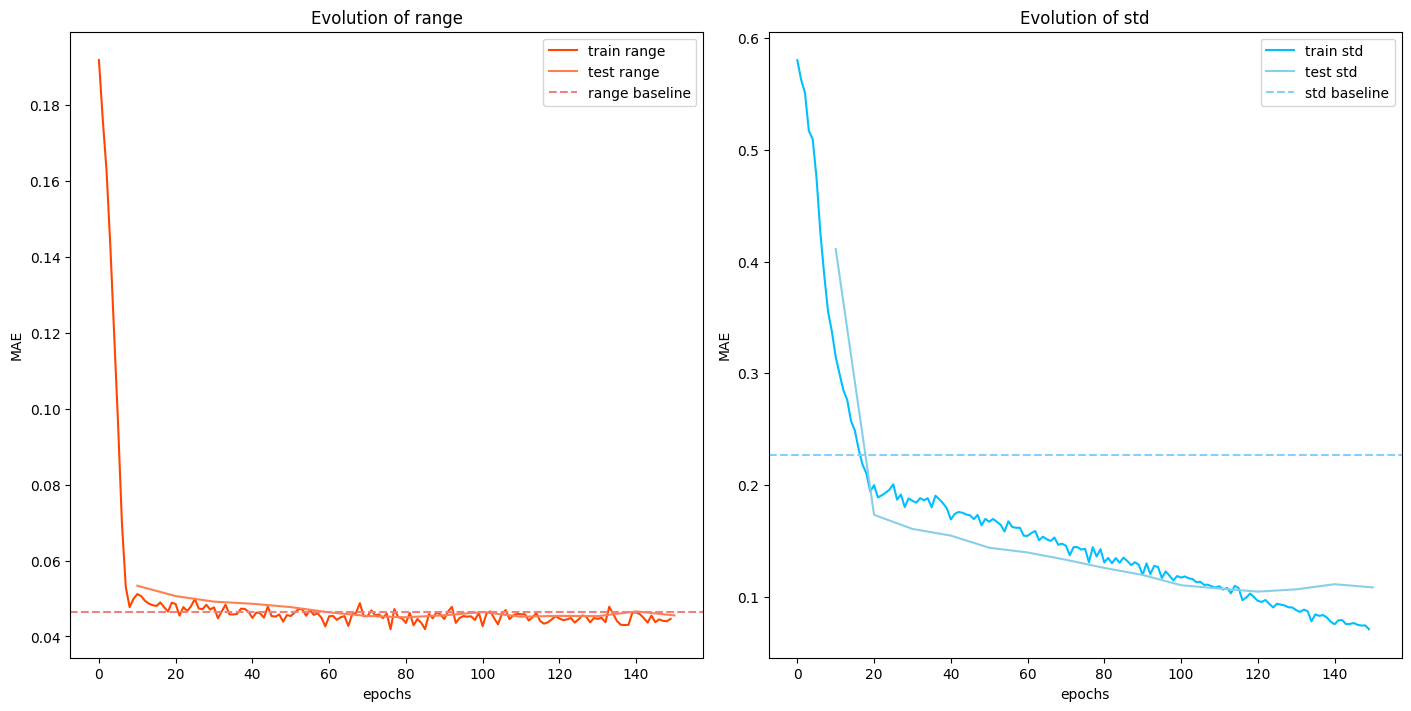

In [422]:
fig_cnn = plot_loss(all_loss_train_grid, all_loss_test_grid)

## NLS

### Functions

In [355]:
class GridNLSDataset(Dataset):
    def __init__(self, time_steps, theta, deepset):
        self.time_steps = time_steps
        self.theta = theta
        self.deepset = deepset

        self.theta_perm = theta.clone()
        for i in range(n_train):
            pi = torch.randperm(m_train)
            self.theta_perm[i*m_train+torch.arange(m_train)] = theta[i*m_train+pi[torch.arange(m_train)]]
            
    def __len__(self):
        return len(self.theta)*2

    def __getitem__(self, idx):

        nm = len(self.theta)

        if idx < nm :
            data = torch.load(file+"/grids/train_grid"+str(idx)+".pt", weights_only=False)
            return (data, self.time_steps[idx], self.theta[idx], torch.tensor(1))
        else :
            data = torch.load(file+"/grids/train_grid"+str(idx - nm)+".pt", weights_only=False)
            return (data, self.time_steps[idx - nm], self.theta_perm[idx - nm], torch.tensor(0))

dataset_grid_nls = GridNLSDataset(train_time_steps, train_theta, train_deepset)
loader_grid_nls = DataLoader(dataset_grid_nls, batch_size, shuffle=True)

In [356]:
def epoch_nls(model, optimizer, loader):
    
    model.train()
    CE = nn.CrossEntropyLoss() # torch.nn.BCELoss(reduction="mean") 
    
    sum_loss = []

    for i, (x, time_steps, theta, classi) in enumerate(loader):
        optimizer.zero_grad()

        x, time_steps, theta, label = x.to(device), time_steps.to(device), theta.to(device), classi.to(device).flatten()

        output = model(x, time_steps, theta=theta)
        
        batch_loss = CE(output, label)
        
        batch_loss.backward()
        optimizer.step()
        
        sum_loss.append(batch_loss.item())

    return torch.mean(torch.tensor(sum_loss))

In [372]:
def estimate_likelihood_surface(model, simu, time_steps, theta_grid):
    
    model.eval()
    
    L_values = []
    simu = simu.to(device)
    
    with torch.no_grad():
        t = tqdm(theta_grid)
        for theta in t:
            
            theta_t = theta.clone().unsqueeze(0).tile((len(simu), 1)).to(device)
            h = model(simu, time_steps, theta=theta_t)
            
            # p = torch.softmax(h, dim=1)[:, 1]   # h[:,1]
            # L = p / (1 - p)
            # L_values.append(L)

            logL = h[:,1] - h[:,0]
            L_values.append(logL)

            # L = torch.log(L.unsqueeze(0)).detach().numpy()
            # L = torch.tensor(lg.predict_proba(L.T)[0, 1])     
            
    return torch.stack(L_values)

### Train

In [357]:
model_nls = CNN_network(in_channels=2, option="CNN", nls=True).to(device)
# model_nls.load_state_dict(torch.load(f"results/global_smaller-{n_train}×{m_train}ntrain-{n_test}×{m_test}ntest"+"/models"+"/nls-classifier_model.pth", weights_only=True))

optimizer_nls = torch.optim.Adam(model_nls.parameters(), lr=1e-3)

In [361]:
all_loss_train_nls, time_train_nls = train_test(model_nls, optimizer_nls, loader_grid_nls, epoch_nls, test=False)

Epoch 150/150: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 150/150 [04:54<00:00,  1.96s/it, loss=0.19393937289714813]

Time to train : 294.43s
Train loss : 0.19393937 ± 0.11293917


Text(0, 0.5, 'Cross Entropy')

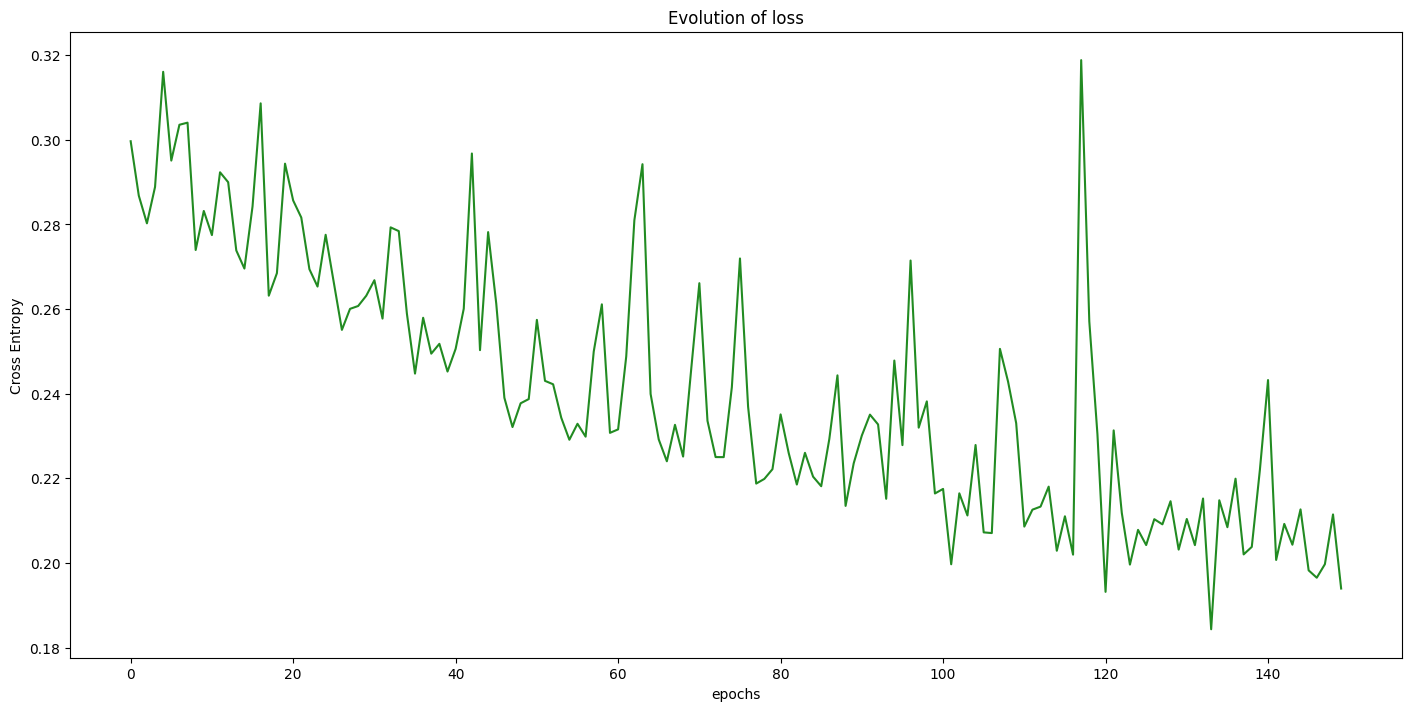

In [370]:
fig_nls, ax = plt.subplots(1, 1, figsize=(14, 7), constrained_layout=True)
ax.plot(all_loss_train_nls, 'forestgreen')

ax.set_title('Evolution of loss')
ax.set_xlabel('epochs')
ax.set_ylabel('Cross Entropy')

### Test

In [373]:
range_min, range_max = 0.05, 0.25
std_min, std_max = 0.1, 1.0

bounds = [(range_min, range_max), (std_min, std_max)]

n_range = 20
n_std = 20

range_vals = torch.linspace(range_min, range_max, n_range)
std_vals = torch.linspace(std_min, std_max, n_std)

R, S = torch.meshgrid(range_vals, std_vals, indexing='ij')
theta_grid = torch.stack([R.flatten(), S.flatten()], dim=1)

In [375]:
time_test_nls = time.time()

with torch.no_grad():
    for data_test, time_steps_test, theta_test, _ in loader_grid_test : 
        L_values = estimate_likelihood_surface(model_nls, data_test, time_steps_test, theta_grid)
        output = theta_grid[torch.argmax(L_values,dim=0)]
        all_loss_test_nls = torch.abs(output - theta_test).detach().numpy()
        theta_final_nls = output.detach().numpy()
        
time_test_nls = time.time() - time_test_nls

print(f"\nTime to test : {time_test_nls:.2f}s")

print("Test loss :", np.mean(all_loss_test_nls,axis=0), "±", np.std(all_loss_test_nls,axis=0))

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 400/400 [01:07<00:00,  5.92it/s]


Time to test : 67.53s
Test loss : [0.07946552 0.08818614] ± [0.05207456 0.05629205]


## Maximum likelihood

In [279]:
def mle_gstlearn(db):
    
    modelnew = gl.Model.createFromParam(gl.ECov.MATERN,param = 1)
    mop = gl.ModelOptimParam.create(False) 
    modelnew.fitNew(db=db,verbose = False, mop = mop, nb_neighVecchia=20)

    # print(modelnew.getCovAniso(0).getSill(0,0) / modelnew.getCovAniso(0).getScale(0)**2)
   
    return modelnew.getCovAniso(0).getScale(0), np.sqrt(modelnew.getCovAniso(0).getSill(0,0))

In [280]:
all_loss_test_ML = np.zeros((len(sampling_test),theta_size))
theta_final_ML = np.zeros((len(sampling_test),theta_size))

time_test_ML = time.time()

for i, (data_test, _, theta_test, _) in enumerate(sampling_test) : 

    # output, _ = mle_matern(data_test[["x1","x2"]],data_test["Simu"])
    output = mle_gstlearn(data_test)

    all_loss_test_ML[i] = np.abs(output - np.array(theta_test))
    theta_final_ML[i] = output

    print(i, end='|')

    # print(f"| RANGE {output[0]:.4f} - {theta_test[0]:.4f} = {abs(output[0]-theta_test[0]):.4f} | STD {output[1]:.4f} - {theta_test[1]:.4f} = {abs(output[1]-theta_test[1]):.4f} |")

time_test_ML = time.time() - time_test_ML

print(f"\n\nTime to test : {time_test_ML:.2f}s")

print("Test loss :", np.mean(all_loss_test_ML,axis=0), "±", np.std(all_loss_test_ML,axis=0))

No Optimizer could be created
0|No Optimizer could be created
1|No Optimizer could be created
2|No Optimizer could be created
3|No Optimizer could be created
4|No Optimizer could be created
5|No Optimizer could be created
6|No Optimizer could be created
7|No Optimizer could be created
8|No Optimizer could be created
9|No Optimizer could be created
10|No Optimizer could be created
11|No Optimizer could be created
12|No Optimizer could be created
13|No Optimizer could be created
14|No Optimizer could be created
15|No Optimizer could be created
16|No Optimizer could be created
17|No Optimizer could be created
18|No Optimizer could be created
19|No Optimizer could be created
20|No Optimizer could be created
21|No Optimizer could be created
22|No Optimizer could be created
23|No Optimizer could be created
24|No Optimizer could be created
25|No Optimizer could be created
26|No Optimizer could be created
27|No Optimizer could be created
28|No Optimizer could be created
29|

Time to test : 0.0

## Conclusion

/tmp/ipykernel_7704/4121961618.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[0].boxplot(loss_range, labels=methods, patch_artist=True,
/tmp/ipykernel_7704/4121961618.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[1].boxplot(loss_std, labels=methods, patch_artist=True,


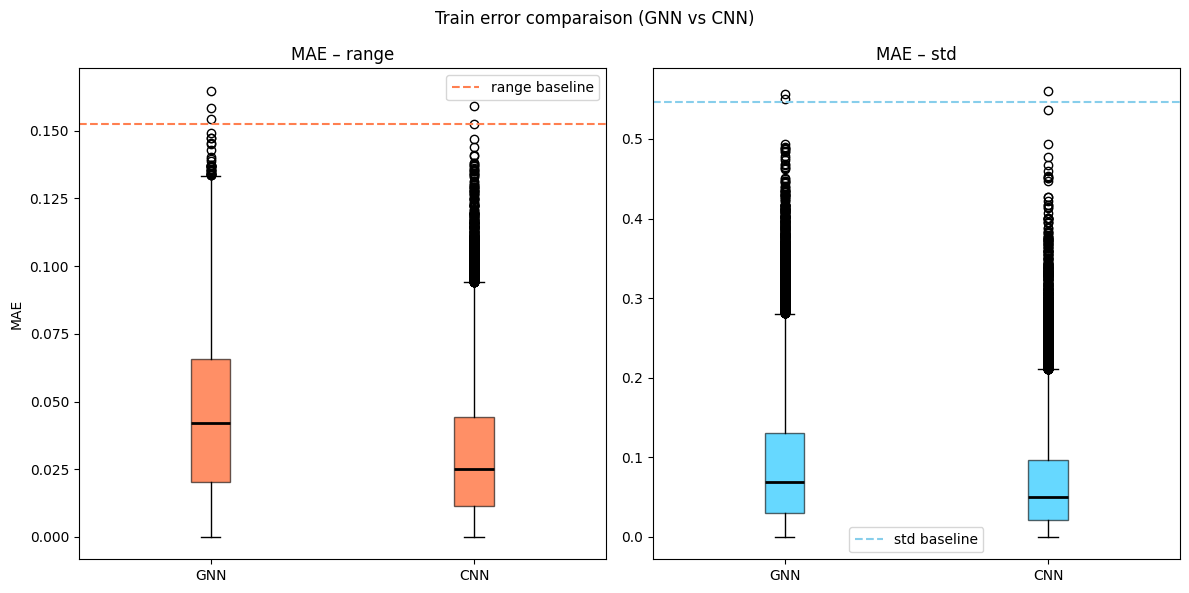

In [70]:
methods = ['GNN', 'CNN']

loss_range = [
    all_loss_train_graph[-1][:, 0],
    all_loss_train_grid[-1][:, 0],
]

loss_std = [
    all_loss_train_graph[-1][:, 1],
    all_loss_train_grid[-1][:, 1],
]

### Boxplot
fig_box_train, axs = plt.subplots(1, 2, figsize=(12, 6))

axs[0].boxplot(loss_range, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='orangered', alpha=0.6), 
               medianprops=dict(linestyle='-', linewidth=2, color='black'))
axs[0].set_title("MAE – range")
axs[0].set_ylabel("MAE")

axs[1].boxplot(loss_std, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='deepskyblue', alpha=0.6),
               medianprops=dict(linestyle='-', linewidth=2, color='black'))
axs[1].set_title("MAE – std")

axs[0].axhline(based[0],color='coral', ls='--', label='range baseline')
axs[1].axhline(based[1],color='skyblue', ls='--', label='std baseline')

axs[0].legend()
axs[1].legend()

plt.suptitle("Train error comparaison (GNN vs CNN)")
plt.tight_layout()
plt.show()

# fig_box_train.savefig(path+"/conclusion_graphs"+"/score_train.pdf", format="pdf", bbox_inches="tight")
fig_box_train.savefig(path+"/conclusion_graphs"+"/score_train.png", format="png", bbox_inches="tight")

/tmp/ipykernel_7704/3946810622.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[0].boxplot(loss_range, labels=methods, patch_artist=True,
/tmp/ipykernel_7704/3946810622.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[1].boxplot(loss_std, labels=methods, patch_artist=True,


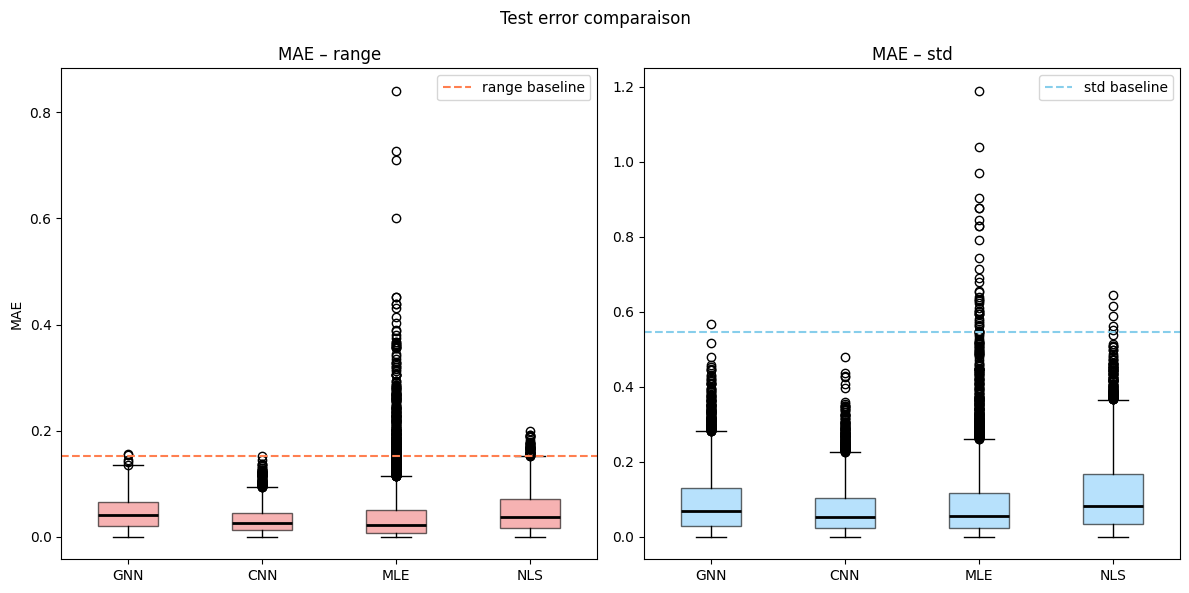

In [71]:
methods = ['GNN', 'CNN', 'MLE', 'NLS']

loss_range = [
    all_loss_test_graph[-1][:, 0],
    all_loss_test_grid[-1][:, 0],
    all_loss_test_ML[:, 0],
    all_loss_test_nls[:, 0]
]

loss_std = [
    all_loss_test_graph[-1][:, 1],
    all_loss_test_grid[-1][:, 1],
    all_loss_test_ML[:, 1],
    all_loss_test_nls[:, 1]
]

### Boxplot
fig_box_test, axs = plt.subplots(1, 2, figsize=(12, 6))

axs[0].boxplot(loss_range, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='lightcoral', alpha=0.6),
               medianprops=dict(linestyle='-', linewidth=2, color='black'))
axs[0].set_title("MAE – range")
axs[0].set_ylabel("MAE")

axs[1].boxplot(loss_std, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='lightskyblue', alpha=0.6),
               medianprops=dict(linestyle='-', linewidth=2, color='black'))
axs[1].set_title("MAE – std")

axs[0].axhline(based[0],color='coral', ls='--', label='range baseline')
axs[1].axhline(based[1],color='skyblue', ls='--', label='std baseline')

axs[0].legend()
axs[1].legend()

fig_box_test.suptitle("Test error comparaison")
plt.tight_layout()
plt.show()

# fig_box_test.savefig(path+"/conclusion_graphs"+"/score_test.pdf", format="pdf", bbox_inches="tight")
fig_box_test.savefig(path+"/conclusion_graphs"+"/score_test.png", format="png", bbox_inches="tight")

axs[0].set_ylim(top=based[0]+.05)
axs[1].set_ylim(top=based[1]+.05)

fig_box_test.suptitle("Test error comparaison cropped")

fig_box_test.savefig(path+"/conclusion_graphs"+"/score_test_cropped.png", format="png", bbox_inches="tight")

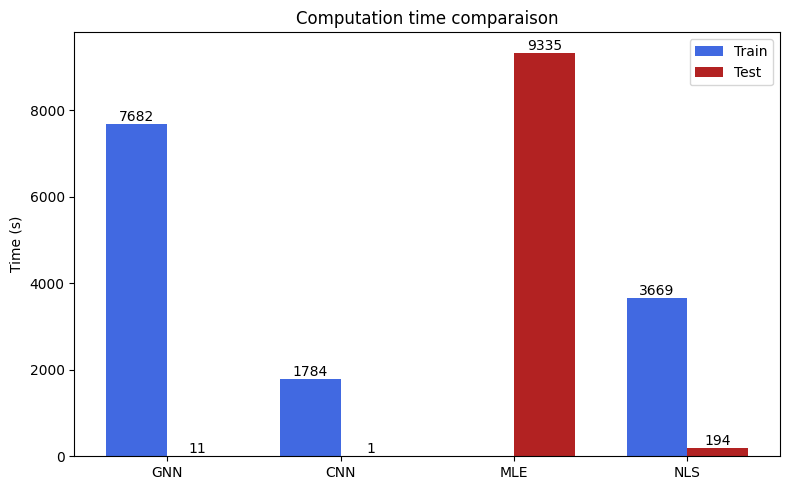

In [63]:
### Time
train_times = [time_train_graph, time_train_grid, np.nan, time_train_nls]  
test_times = [time_test_graph, time_test_grid, time_test_ML, time_test_nls]

x = np.arange(len(methods))
width = 0.35

fig_time, ax = plt.subplots(figsize=(8, 5))
bar1 = ax.bar(x - width/2, train_times, width, label='Train', color='royalblue')
bar2 = ax.bar(x + width/2, test_times, width, label='Test', color='firebrick')

for rect in bar1 + bar2:
    height = rect.get_height()
    plt.text(rect.get_x() + rect.get_width() / 2.0, height, f'{height:.0f}', ha='center', va='bottom')

ax.set_xticks(x)
ax.set_xticklabels(methods)
ax.set_ylabel("Time (s)")
ax.set_title("Computation time comparaison")
ax.legend()

plt.tight_layout()
plt.show()

# fig_time.savefig(path+"/conclusion_graphs"+"/time.pdf", format="pdf", bbox_inches="tight")
fig_time.savefig(path+"/conclusion_graphs"+"/time.png", format="png", bbox_inches="tight")

IndexError: list index out of range

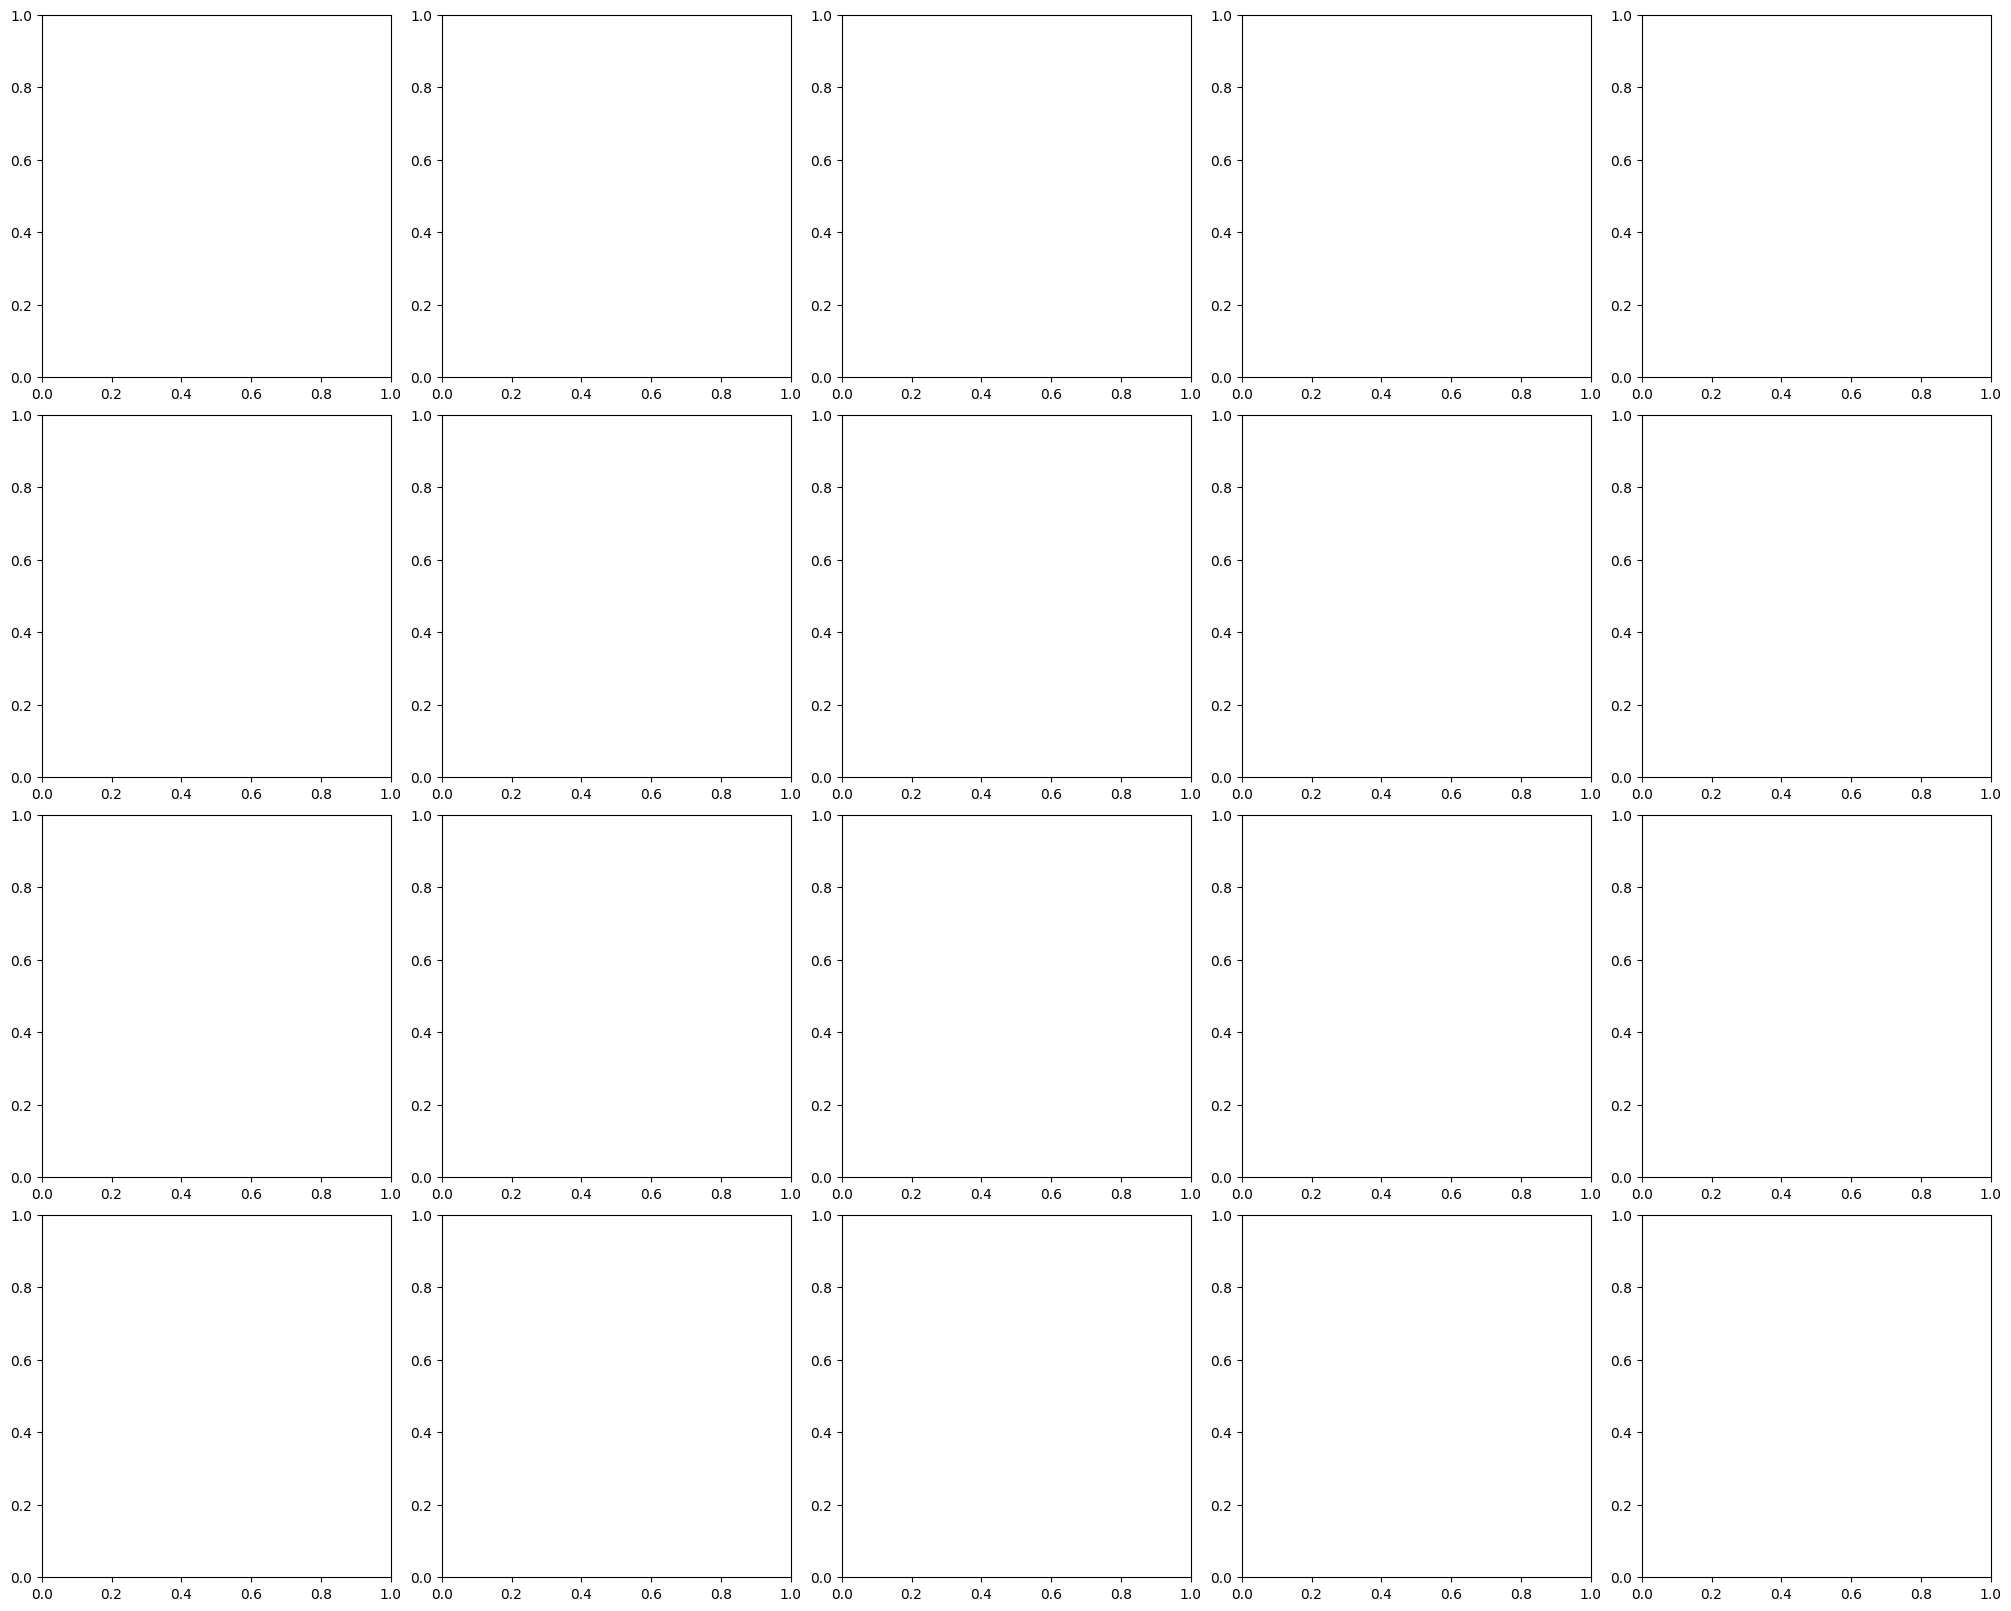

In [73]:
n = 4
fig_map, axs = plt.subplots(n, 5, figsize=(20,n*4), constrained_layout=True)

methods = ["GNN", "CNN", "MLE", "NLS"]
thetas_final = [theta_final_graph, theta_final_grid, theta_final_ML, theta_final_nls]
losses = [all_loss_test_graph[-1], all_loss_test_grid[-1], all_loss_test_ML, all_loss_test_nls]

for i in range(n):
    true_theta = sampling_test[i][1].detach().numpy()
    sample = simulation_matern(grid(), true_theta[0], true_theta[1], plot=False)
    
    sample = sample['Simu'].reshape(100, 100)
    axs[i,0].imshow(sample, cmap='viridis', extent=[0,1,0,1])
        
    axs[i,0].set_xlabel('x1')
    axs[i,0].set_ylabel('x2')
    axs[i,0].set_title(r'Simu with true $\theta$'+'\n'+str(true_theta))
    
    for j, (method, thetas, l) in enumerate(zip(methods, thetas_final,losses)) :

        sample = simulation_matern(grid(), thetas[i,0], thetas[i,1], plot=False)
            
        sample = sample['Simu'].reshape(100, 100)
        axs[i,j+1].imshow(sample, cmap='viridis', extent=[0,1,0,1]) #, origin='lower', extent=[0,1,0,1], cmap='viridis')
            
        axs[i,j+1].set_xlabel('x1')
        axs[i,j+1].set_ylabel('x2')
        axs[i,j+1].set_title(r'Simu with $\theta$ from '+method+'\n'+str(thetas[i]))
        

fig_map.suptitle(r"Visualisation comparaison on "+str(n)+r" different $\theta$", fontsize=16)

# fig_map.savefig(path+"/conclusion_graphs"+"/visualisation.pdf", format="pdf", bbox_inches="tight")
fig_map.savefig(path+"/conclusion_graphs"+"/visualisation.png", format="png", bbox_inches="tight")

plt.show()

tensor([0.1525, 0.5463], dtype=torch.float64)


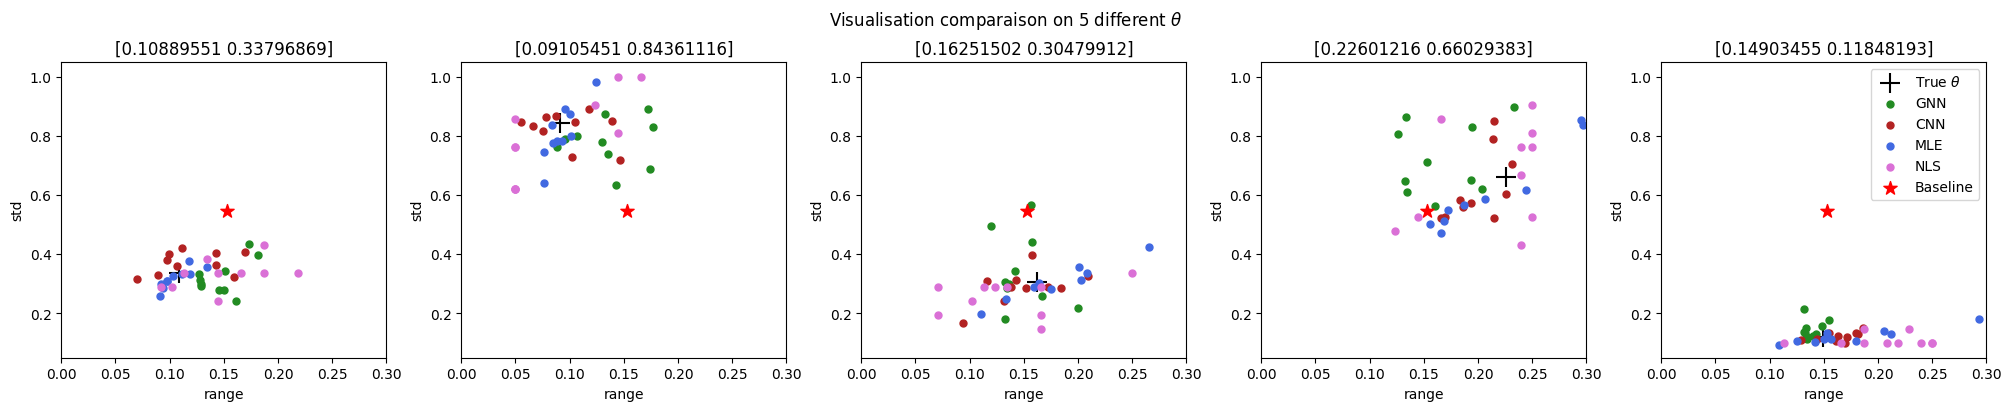

In [75]:
methods = ["GNN", "CNN", "MLE", "NLS"]
colors = ["forestgreen", "firebrick", "royalblue", "orchid"]
thetas_final = [theta_final_graph, theta_final_grid, theta_final_ML, theta_final_nls]

fig_target, axs = plt.subplots(1, 5, figsize=(20,4), constrained_layout=True)

_, based = baseline_mae(dataset_graph)
print(based)

for j in range(min(m_test,5)):
    
    true_theta = sampling_test[j][1].detach().numpy()

    axs[j].scatter(true_theta[0], true_theta[1], s=200, color='black', marker="+", label=r"True $\theta$") 
        
    axs[j].set_xlabel('range')
    axs[j].set_ylabel('std')
    axs[j].set_title(str(true_theta))

    axs[j].set_xlim([range_min-.05, range_max+.05])
    axs[j].set_ylim([std_min-.05, std_max+.05])

    for method, color, thetas in zip(methods, colors, thetas_final) :

        axs[j].scatter(thetas[np.arange(n_test)*m_test+j,0],
                       thetas[np.arange(n_test)*m_test+j,1],
                       s=100, color=color, marker=".", label=method) 

    axs[j].scatter(based[0],based[1], s=100, color='red', marker="*",label='Baseline')

plt.suptitle(r"Visualisation comparaison on 5 different $\theta$")
plt.legend()

# fig_target.savefig(path+"/conclusion_graphs"+"/target.pdf", format="pdf", bbox_inches="tight")
fig_target.savefig(path+"/conclusion_graphs"+"/target.png", format="png", bbox_inches="tight")

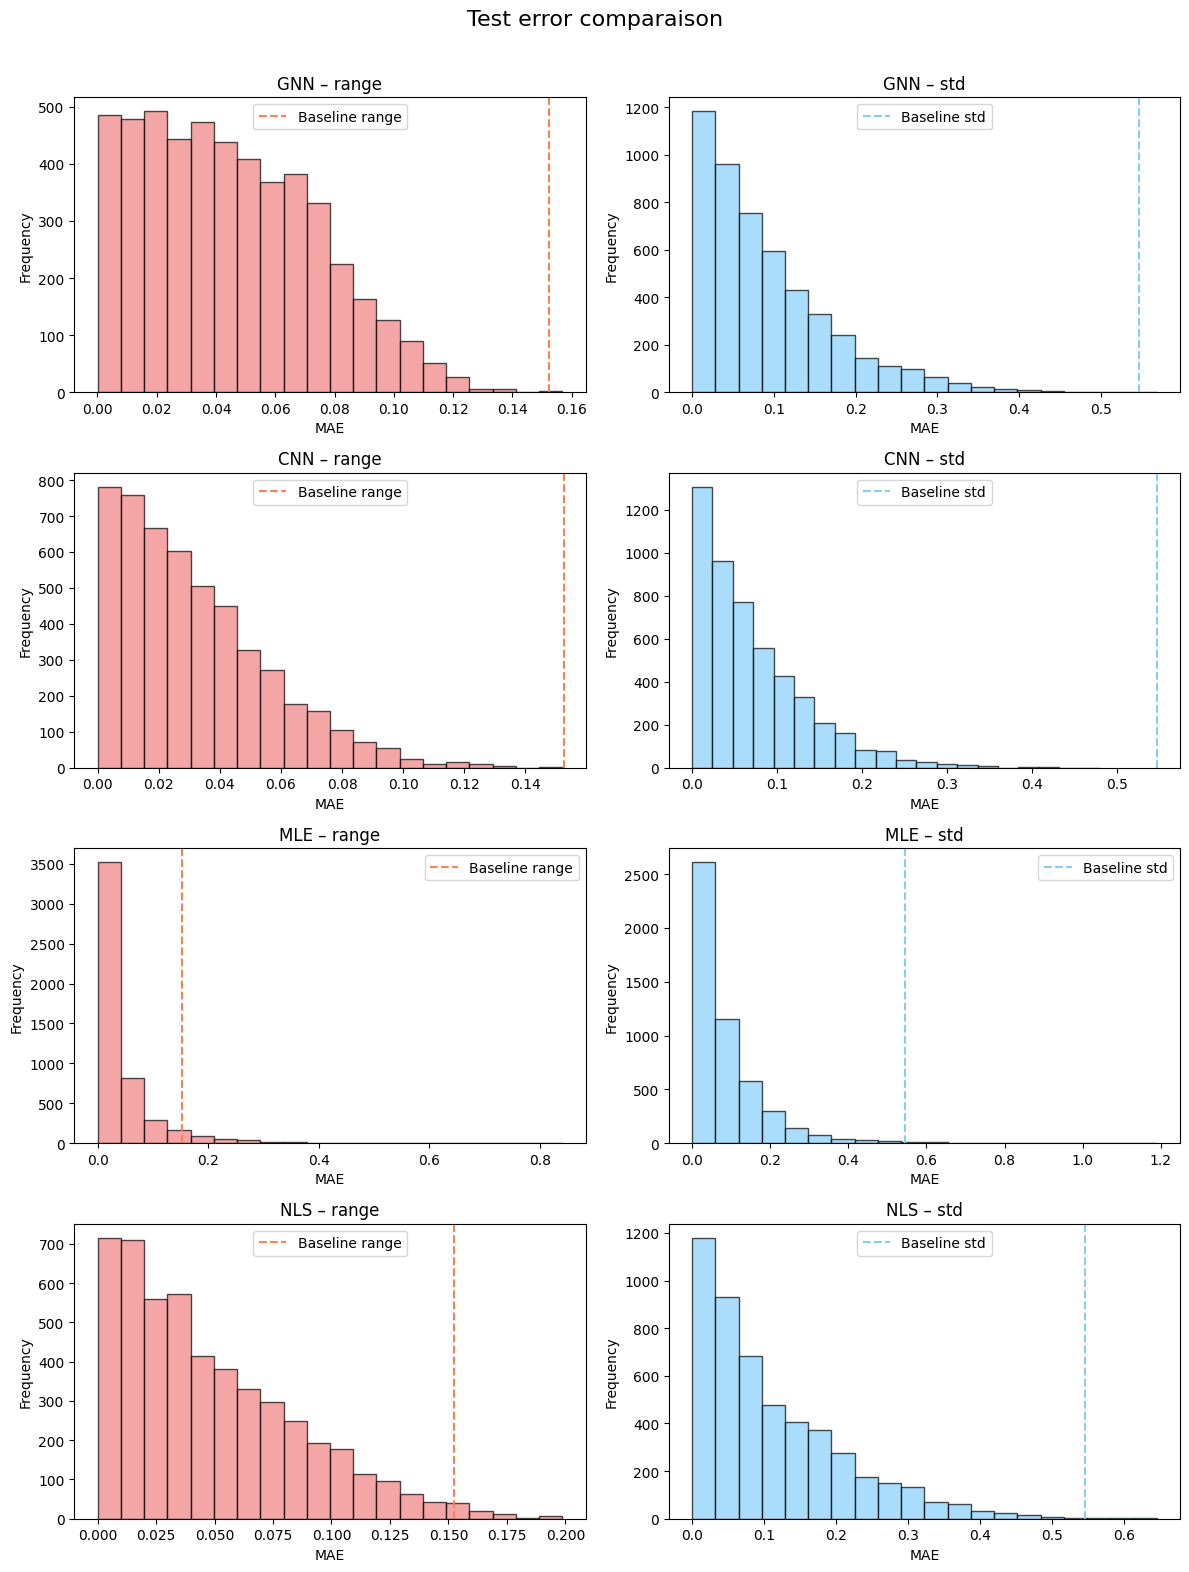

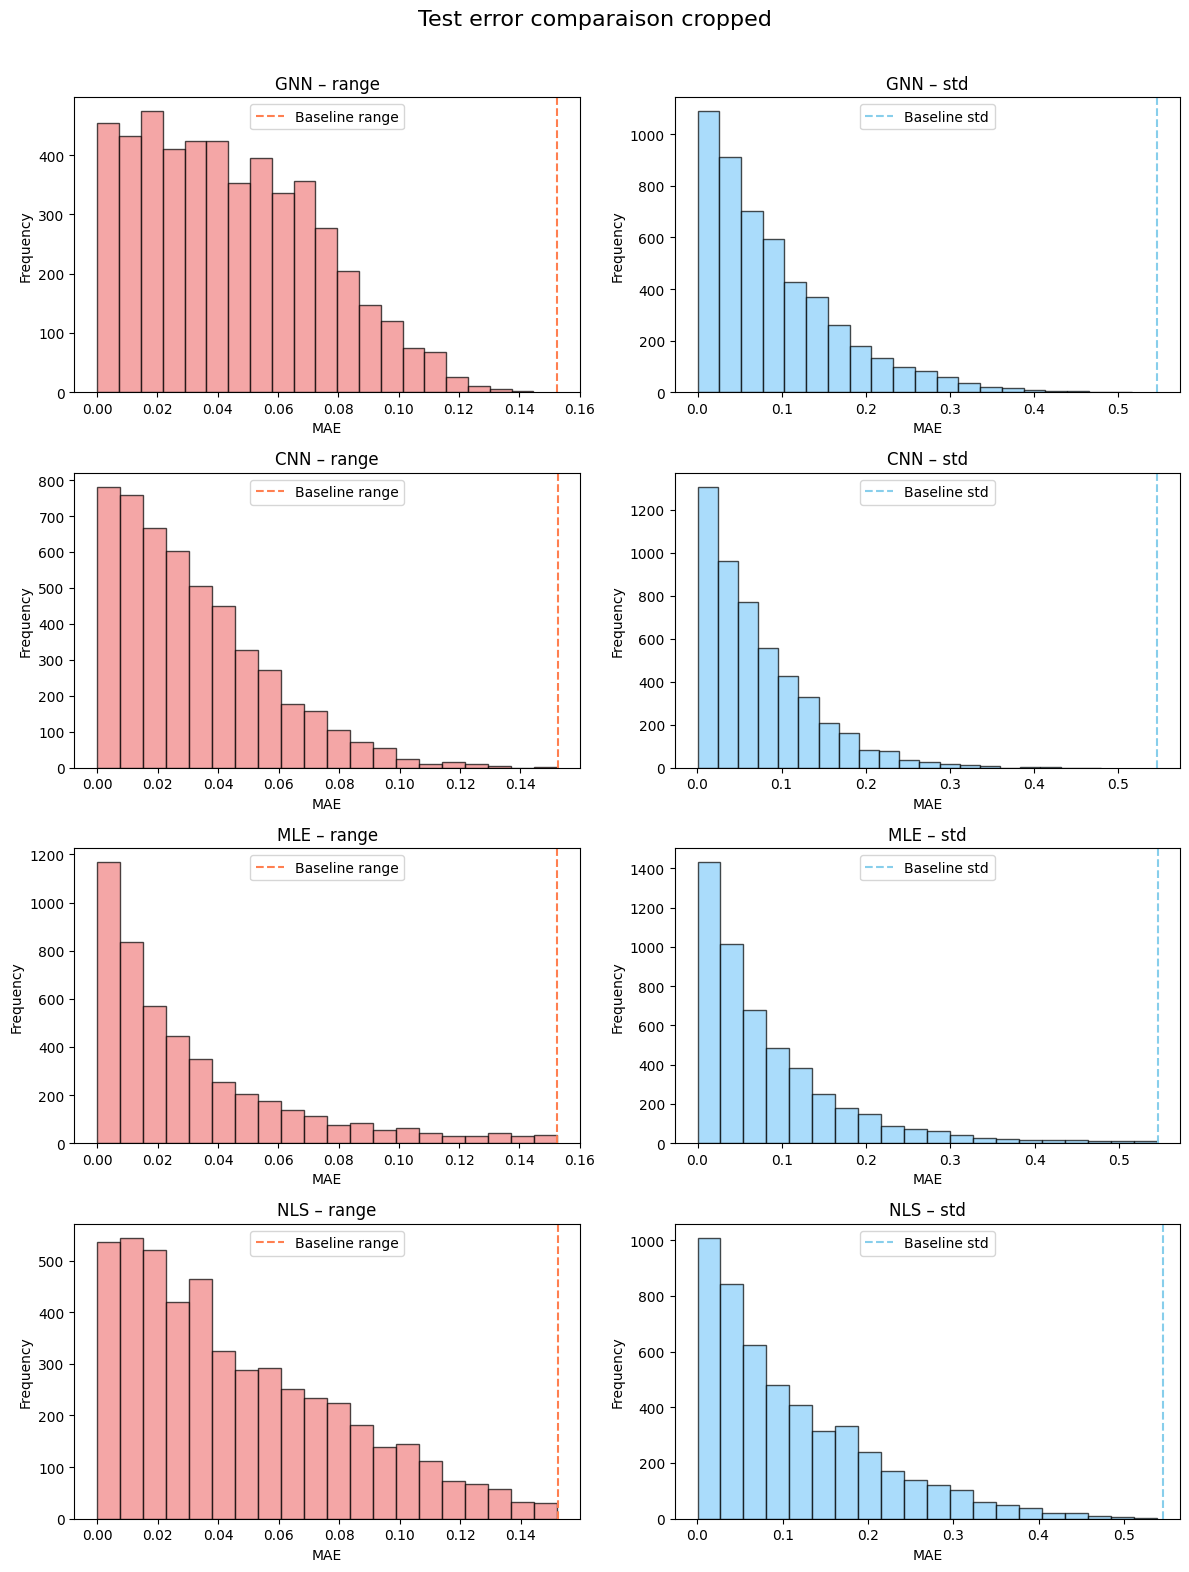

In [72]:
methods = ['GNN', 'CNN', 'MLE', 'NLS']

loss_range = [
    all_loss_test_graph[-1][:, 0],
    all_loss_test_grid[-1][:, 0],
    all_loss_test_ML[:, 0],
    all_loss_test_nls[:, 0]
]

loss_std = [
    all_loss_test_graph[-1][:, 1],
    all_loss_test_grid[-1][:, 1],
    all_loss_test_ML[:, 1],
    all_loss_test_nls[:, 1]
]

fig_hist, axs = plt.subplots(len(loss_range), 2, figsize=(12, 4*len(loss_range)))
fig_hist.suptitle("Test error comparaison", fontsize=16)

for i, method in enumerate(methods):

    axs[i, 0].hist(loss_range[i], bins=20, color='lightcoral', alpha=0.7, edgecolor='black')
    axs[i, 0].axvline(based[0], color='coral', linestyle='--', label='Baseline range')
    axs[i, 0].set_title(f"{method} – range")
    axs[i, 0].set_xlabel("MAE")
    axs[i, 0].set_ylabel("Frequency")
    axs[i, 0].legend()

    axs[i, 1].hist(loss_std[i], bins=20, color='lightskyblue', alpha=0.7, edgecolor='black')
    axs[i, 1].axvline(based[1], color='skyblue', linestyle='--', label='Baseline std')
    axs[i, 1].set_title(f"{method} – std")
    axs[i, 1].set_xlabel("MAE")
    axs[i, 1].set_ylabel("Frequency")
    axs[i, 1].legend()

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

fig_hist.savefig(path+"/conclusion_graphs"+"/score_test_hist.png", format="png", bbox_inches="tight")

loss_range = [
    all_loss_test_graph[-1][:, 0][all_loss_test_graph[-1][:, 0] < based[0].detach().numpy()],
    all_loss_test_grid[-1][:, 0][all_loss_test_grid[-1][:, 0] < based[0].detach().numpy()],
    all_loss_test_ML[:, 0][all_loss_test_ML[:, 0] < based[0].detach().numpy()],
    all_loss_test_nls[:, 0][all_loss_test_nls[:, 0] < based[0].detach().numpy()]
]

loss_std = [
    all_loss_test_graph[-1][:, 1][all_loss_test_graph[-1][:, 1] < based[1].detach().numpy()],
    all_loss_test_grid[-1][:, 1][all_loss_test_grid[-1][:, 1] < based[1].detach().numpy()],
    all_loss_test_ML[:, 1][all_loss_test_ML[:, 1] < based[1].detach().numpy()],
    all_loss_test_nls[:, 1][all_loss_test_nls[:, 1] < based[1].detach().numpy()]
]

fig_hist, axs = plt.subplots(len(loss_range), 2, figsize=(12, 4*len(loss_range)))
fig_hist.suptitle("Test error comparaison cropped", fontsize=16)

for i, method in enumerate(methods):

    axs[i, 0].hist(loss_range[i], bins=20, color='lightcoral', alpha=0.7, edgecolor='black')
    axs[i, 0].axvline(based[0], color='coral', linestyle='--', label='Baseline range')
    axs[i, 0].set_title(f"{method} – range")
    axs[i, 0].set_xlabel("MAE")
    axs[i, 0].set_ylabel("Frequency")
    axs[i, 0].legend()

    axs[i, 1].hist(loss_std[i], bins=20, color='lightskyblue', alpha=0.7, edgecolor='black')
    axs[i, 1].axvline(based[1], color='skyblue', linestyle='--', label='Baseline std')
    axs[i, 1].set_title(f"{method} – std")
    axs[i, 1].set_xlabel("MAE")
    axs[i, 1].set_ylabel("Frequency")
    axs[i, 1].legend()

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

fig_hist.savefig(path+"/conclusion_graphs"+"/score_test_hist_cropped.png", format="png", bbox_inches="tight")

In [50]:
results = {
    "all_loss_train": {
        "GNN": all_loss_train_graph,
        "CNN": all_loss_train_grid,
    },
    "all_loss_test": {
        "GNN": all_loss_test_graph,
        "CNN": all_loss_test_grid,
        "MLE": all_loss_test_ML,
        "NLS": all_loss_test_nls,
    },
    "theta_final": {
        "GNN": theta_final_graph,
        "CNN": theta_final_grid,
        "MLE": theta_final_ML,
        "NLS": theta_final_nls,
    },
    "times": {
        "time_train_graph": time_train_graph,
        "time_test_graph": time_test_graph,
        "time_train_grid": time_train_grid,
        "time_test_grid": time_test_grid,
        "time_test_ML": time_test_ML,
        "time_train_nls": time_train_nls,
        "time_test_nls": time_test_nls,
    },
    "meta": {
        "n_train": n_train, "m_train": m_train,
        "n_test": n_test, "m_test": m_test,
    }
}

torch.save(results, path + "/results.pt")